In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from rdflib import OWL, RDF, RDFS, Graph, Namespace, URIRef

sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd().parent
ONTOLOGY_PATH = BASE_DIR / "data" / "wittgensteiniana_final.ttl"

if not ONTOLOGY_PATH.exists():
    raise FileNotFoundError(f"Ontology file not found: {ONTOLOGY_PATH}")

graph = Graph()
graph.parse(str(ONTOLOGY_PATH))

ID = Namespace("http://wittgensteiniana.michelepasin.org/id/")
EX = Namespace("http://example.org/wittgensteiniana/")
SCHEMA = Namespace("https://schema.org/")

print(f"Loaded triples: {len(graph):,}")


Loaded triples: 15,567


In [2]:
def get_local_name(uri):
    uri = str(uri)
    return uri.rsplit("#", 1)[-1].rsplit("/", 1)[-1]


def get_resource_types(resource):
    return set(graph.objects(resource, RDF.type))


## Focus on the Tractatus



In [3]:
TRACTATUS_URI = ID["tractatus"]

print("Tractatus URI:", TRACTATUS_URI)
print("Is Book:", (TRACTATUS_URI, RDF.type, SCHEMA.Book) in graph)

parts = list(graph.subjects(SCHEMA.isPartOf, TRACTATUS_URI))
print(f"Incoming isPartOf (parts): {len(parts):,}")

translations = list(graph.subjects(SCHEMA.translationOfWork, TRACTATUS_URI))
print(f"Incoming translationOfWork (editions): {len(translations):,}")

author = list(graph.objects(TRACTATUS_URI, EX.hasAuthor))
print(f"hasAuthor (outgoing): {len(author):,}")

print("Date published:", list(graph.objects(TRACTATUS_URI, SCHEMA.datePublished)))


Tractatus URI: http://wittgensteiniana.michelepasin.org/id/tractatus
Is Book: True
Incoming isPartOf (parts): 533
Incoming translationOfWork (editions): 2
hasAuthor (outgoing): 1
Date published: [rdflib.term.Literal('1921')]


## collect resources related to the Tractatus

Collecting resources connected to the Tractatus book via:

- `isPartOf` (incoming) — chapters and German text fragments
- `translationOfWork` (incoming) — the English editions
- `hasAuthor` (outgoing) — the author resource



In [4]:
start_resources = set(graph.subjects(SCHEMA.isPartOf, TRACTATUS_URI))
start_resources.update(graph.subjects(SCHEMA.translationOfWork, TRACTATUS_URI))
start_resources.update(graph.objects(TRACTATUS_URI, EX.hasAuthor))

print(f"Start resources (1st level): {len(start_resources):,}")


Start resources (1st level): 536


In [5]:
#collecting all incoming and outgoing triples (excluding rdf:type)
unique_triples = set()

for resource in start_resources:
    for s, p, o in graph.triples((resource, None, None)):
        if p != RDF.type:
            unique_triples.add((s, p, o))
    for s, p, o in graph.triples((None, None, resource)):
        if p != RDF.type:
            unique_triples.add((s, p, o))

print(f"Unique triples around the Tractatus: {len(unique_triples):,}")


Unique triples around the Tractatus: 3,815


## Aggregate relations to class level

Converting individual resource triples into unique combinations:
`subject_class — predicate — object_class`



In [6]:
class_relations = []

for subject, predicate, obj in unique_triples:
    if not isinstance(subject, URIRef) or not isinstance(obj, URIRef):
        continue

    subject_types = get_resource_types(subject)
    object_types = get_resource_types(obj)

    for subject_type in subject_types:
        for object_type in object_types:
            class_relations.append({
                "subject_class": get_local_name(subject_type),
                "subject_class_uri": str(subject_type),
                "predicate": get_local_name(predicate),
                "predicate_uri": str(predicate),
                "object_class": get_local_name(object_type),
                "object_class_uri": str(object_type),
            })

relations_df = (
    pd.DataFrame(class_relations)
    .drop_duplicates()
    .reset_index(drop=True)
)

print(f"Unique class-level relations: {len(relations_df)}")
relations_df.head(10)


Unique class-level relations: 20


,subject_class,subject_class_uri,predicate,predicate_uri,object_class,object_class_uri
0,CreativeWork,https://schema.org/CreativeWork,exampleOfWork,https://schema.org/exampleOfWork,Chapter,https://schema.org/Chapter
1,CreativeWork,https://schema.org/CreativeWork,exampleOfWork,https://schema.org/exampleOfWork,Thesis,http://example.org/wittgensteiniana/Thesis
2,TextFragment,http://example.org/wittgensteiniana/TextFragment,exampleOfWork,https://schema.org/exampleOfWork,Chapter,https://schema.org/Chapter
3,TextFragment,http://example.org/wittgensteiniana/TextFragment,exampleOfWork,https://schema.org/exampleOfWork,Thesis,http://example.org/wittgensteiniana/Thesis
4,CreativeWork,https://schema.org/CreativeWork,isPartOf,https://schema.org/isPartOf,Book,https://schema.org/Book
5,TextFragment,http://example.org/wittgensteiniana/TextFragment,isPartOf,https://schema.org/isPartOf,Book,https://schema.org/Book
6,Chapter,https://schema.org/Chapter,hasTextFragment,http://example.org/wittgensteiniana/hasTextFra...,CreativeWork,https://schema.org/CreativeWork
7,Chapter,https://schema.org/Chapter,hasTextFragment,http://example.org/wittgensteiniana/hasTextFra...,TextFragment,http://example.org/wittgensteiniana/TextFragment
8,Thesis,http://example.org/wittgensteiniana/Thesis,hasTextFragment,http://example.org/wittgensteiniana/hasTextFra...,CreativeWork,https://schema.org/CreativeWork
9,Thesis,http://example.org/wittgensteiniana/Thesis,hasTextFragment,http://example.org/wittgensteiniana/hasTextFra...,TextFragment,http://example.org/wittgensteiniana/TextFragment


## Basic statistics



In [7]:
print("Predicate frequency")
predicate_counts = (
    relations_df
    .groupby("predicate")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(predicate_counts)


Predicate frequency


,predicate,count
0,isPartOf,8
1,exampleOfWork,4
2,hasTextFragment,4
3,mentions,2
4,hasAuthor,1
5,translationOfWork,1


In [8]:
print("Subject class frequency")
subject_counts = (
    relations_df
    .groupby("subject_class")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(subject_counts)


Subject class frequency


,subject_class,count
0,Chapter,6
1,Thesis,6
2,CreativeWork,3
3,TextFragment,3
4,Book,2


In [9]:
print("Object class frequency")
object_counts = (
    relations_df
    .groupby("object_class")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="count")
)
display(object_counts)


Object class frequency


,object_class,count
0,Book,5
1,Chapter,4
2,Thesis,4
3,DefinedTerm,2
4,CreativeWork,2
5,TextFragment,2
6,Author,1


In [10]:
print("=== Full list of class relations ===")
display(
    relations_df[
        ["subject_class", "predicate", "object_class"]
    ].sort_values(["subject_class", "predicate", "object_class"])
)


=== Full list of class relations ===


,subject_class,predicate,object_class
19,Book,hasAuthor,Author
16,Book,translationOfWork,Book
6,Chapter,hasTextFragment,CreativeWork
7,Chapter,hasTextFragment,TextFragment
10,Chapter,isPartOf,Book
12,Chapter,isPartOf,Chapter
13,Chapter,isPartOf,Thesis
17,Chapter,mentions,DefinedTerm
0,CreativeWork,exampleOfWork,Chapter
1,CreativeWork,exampleOfWork,Thesis


## Visualizations



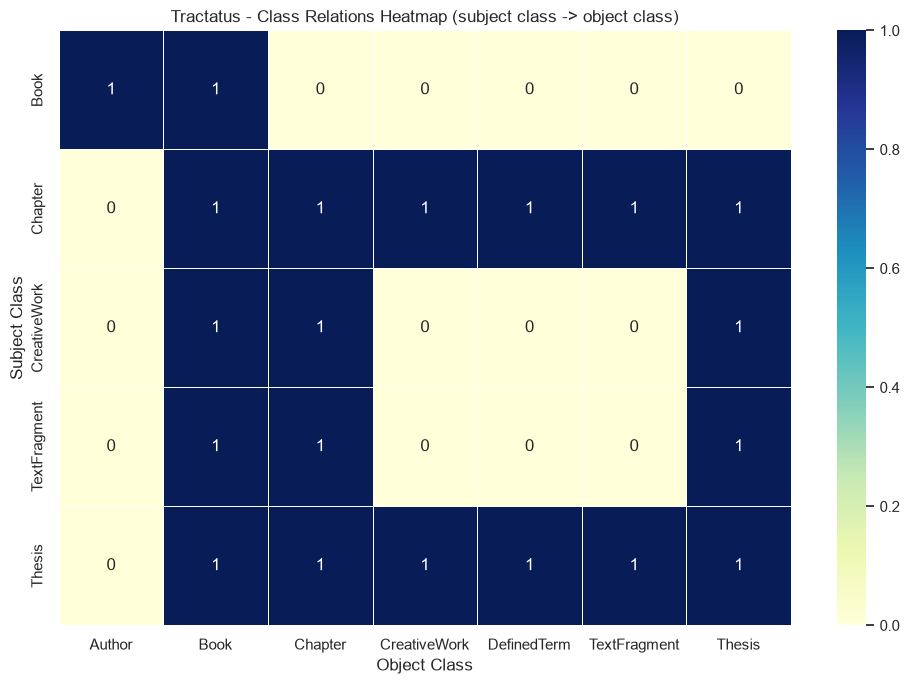

In [11]:
heatmap_data = (
    relations_df
    .groupby(["subject_class", "object_class"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)
plt.title("Tractatus - Class Relations Heatmap (subject class -> object class)")
plt.xlabel("Object Class")
plt.ylabel("Subject Class")
plt.tight_layout()
plt.show()


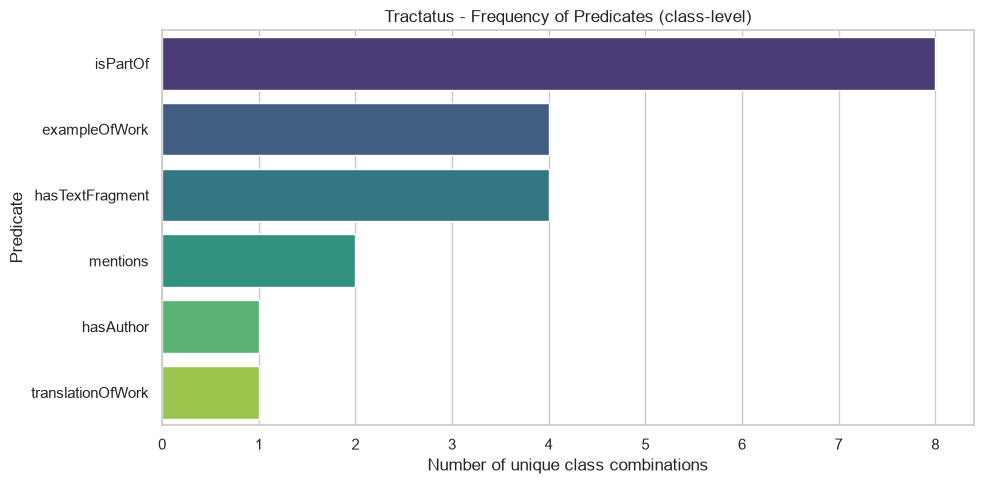

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=predicate_counts,
    x="count",
    y="predicate",
    hue="predicate",
    legend=False,
    palette="viridis"
)
plt.title("Tractatus - Frequency of Predicates (class-level)")
plt.xlabel("Number of unique class combinations")
plt.ylabel("Predicate")
plt.tight_layout()
plt.show()


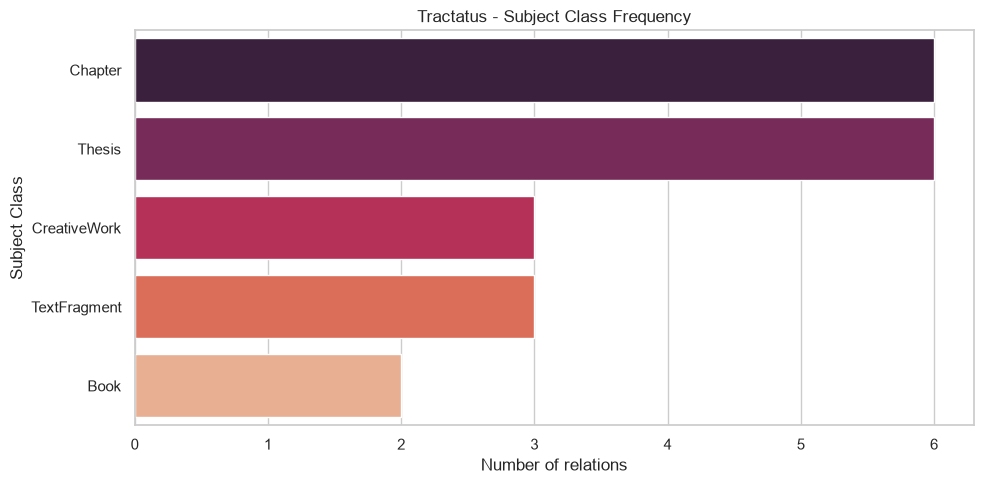

In [13]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=subject_counts,
    x="count",
    y="subject_class",
    hue="subject_class",
    legend=False,
    palette="rocket"
)
plt.title("Tractatus - Subject Class Frequency")
plt.xlabel("Number of relations")
plt.ylabel("Subject Class")
plt.tight_layout()
plt.show()


In [14]:
related_resources = set()

for subject, predicate, obj in unique_triples:
    if isinstance(subject, URIRef):
        related_resources.add(subject)

    if isinstance(obj, URIRef):
        related_resources.add(obj)

print(f"Related resources: {len(related_resources):,}")

type_counter = Counter()
for res in related_resources:
    for t in get_resource_types(res):
        type_counter[get_local_name(t)] += 1

type_df = (
    pd.DataFrame.from_dict(type_counter, orient="index", columns=["count"])
    .sort_values("count", ascending=False)
    .reset_index()
    .rename(columns={"index": "class"})
)

display(type_df)


Related resources: 2,125


,class,count
0,CreativeWork,1578
1,TextFragment,1578
2,Chapter,526
3,Thesis,526
4,DefinedTerm,14
5,Author,4
6,Book,3


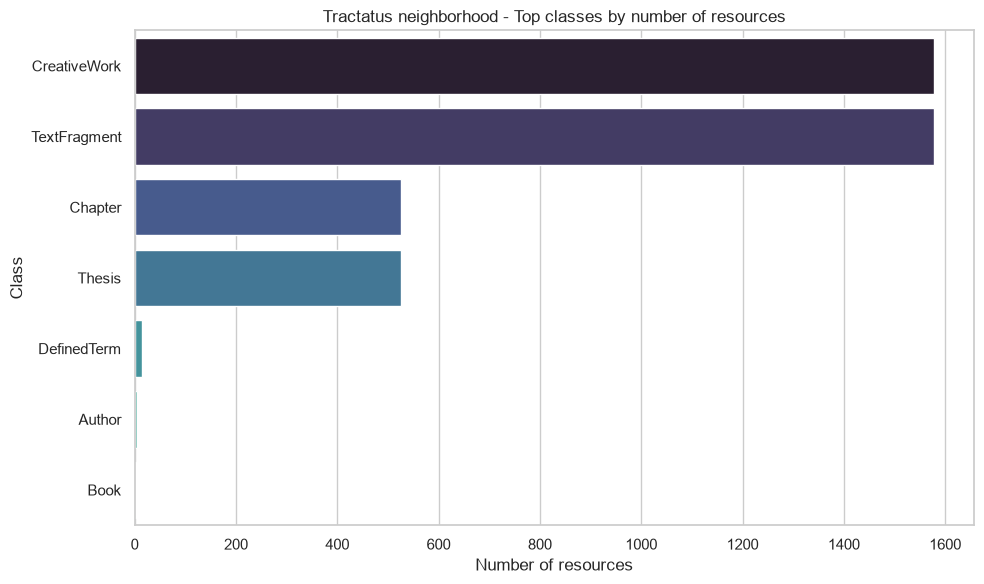

In [15]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=type_df.head(15),
    x="count",
    y="class",
    hue="class",
    legend=False,
    palette="mako"
)
plt.title("Tractatus neighborhood - Top classes by number of resources")
plt.xlabel("Number of resources")
plt.ylabel("Class")
plt.tight_layout()
plt.show()


## Summary

Key outputs for the next stage:

- `relations_df` — unique class-level relations around the Tractatus
- `predicate_counts`, `subject_counts`, `object_counts`
- Neighborhood resource type distribution

These structures will be used for mapping to the WAB ontology classes:
`Werk`, `Bemerkung`, `Part`, `TS`, etc.



In [16]:
print(f"Class-level relations: {len(relations_df)}")
print(f"Neighborhood resources: {len(related_resources):,}")


Class-level relations: 20
Neighborhood resources: 2,125
